## Лабораторная работа № 1 
## Выполнение разведочного анализа больших данных с использованием фреймворка Apache Spark

### Часть 2

В данной части работы рассмотрены:
* разведочный анализ данных;
* работа с Dataframe API фреймворка `Apache Spark`.

Подключаем необходимые библиотеки.

In [1]:
import os
from pyspark.sql import SparkSession, DataFrame
from pyspark import SparkConf
from pyspark.sql.functions import (
    col, lit, sum, mean, when,
    explode, count, desc, floor,
    corr, array_contains, lit, first
)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Сформируем объект конфигурации для `Apache Spark`, указав необходимые параметры.

In [2]:
def create_spark_configuration() -> SparkConf:
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    # Получаем имя пользователя
    user_name = os.getenv("USER")
    
    conf = SparkConf()
    conf.setAppName("lab 1 Test")
    conf.setMaster("yarn")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.executor.memory", "12g")
    conf.set("spark.executor.cores", "8")
    conf.set("spark.executor.instances", "2")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
    conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")

    return conf

Создаём сам объект конфигурации.

In [3]:
conf = create_spark_configuration()

Создаём и выводим на экран сессию `Apache Spark`. В процессе создания сессии происходит подключение к кластеру `Apache Hadoop`, что может занять некоторое время.

In [4]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user0/.ivy2/cache
The jars for the packages stored in: /home/user0/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-77d7dec0-7af1-499c-b4ae-a1ccb8e7160d;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 642ms :: artifacts dl 21ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

Укажем базу данных, которая была создана в первой части лабораторной работы.

In [5]:
database_name = "krutov_database"

Установим созданную базу данных как текущую.

In [6]:
spark.catalog.setCurrentDatabase(database_name)

Прочитаем сохранённую в предыдущей части работы таблицу и загрузим её в `Spark Dataframe`.

In [7]:
df = spark.table("sobd_lab1_table")

Выведем прочитанную таблицу на экран.

In [8]:
df.show()

26/09/17 20:55:29 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

Посмотрим на схему данных.

In [9]:
df.printSchema()

root
 |-- game_id: string (nullable = true)
 |-- game_name: string (nullable = true)
 |-- platform: string (nullable = true)
 |-- storefront: string (nullable = true)
 |-- genre: string (nullable = true)
 |-- publisher_tier: string (nullable = true)
 |-- age_rating: string (nullable = true)
 |-- sale_event_name: string (nullable = true)
 |-- current_price_usd: float (nullable = true)
 |-- original_price_usd: float (nullable = true)
 |-- discount_pct: float (nullable = true)
 |-- estimated_units_sold: float (nullable = true)
 |-- estimated_revenue_usd: float (nullable = true)
 |-- concurrent_players: float (nullable = true)
 |-- peak_ccu_alltime: float (nullable = true)
 |-- review_count: integer (nullable = true)
 |-- positive_reviews: integer (nullable = true)
 |-- negative_reviews: integer (nullable = true)
 |-- steam_rating_pct: float (nullable = true)
 |-- user_score: float (nullable = true)
 |-- metacritic_score: float (nullable = true)
 |-- wishlist_count: integer (nullable = tru

Вычислим количество строк в датафрейме.

In [10]:
df.count()

5584706

Вспомогательные функции для разведочного анализа

Определим набор утилит, которые будем использовать далее:
| Функция | Назначение |
| ------- | ---------- |
| `count_nulls` | Подсчёт количества и доли NULL-значений в колонке |
| `plot_cat_distribution` | Barplot распределения категориального признака (топ-N категорий) |
| `plot_boxplots` | Boxplot для числовых колонок + вывод статистик (min, mean, std, квартили, max) |
| `plot_quant_distribution` | Гистограмма распределения количественного признака с KDE |

In [13]:
def count_nulls(data: DataFrame, column_name: str) -> None:
    """
    Подсчет количества null и not null значений в указанном столбце.
    """
    null_counts = data.select(
        sum(col(column_name).isNull().cast("int"))
    ).collect()[0][0]

    not_null_counts = data.select(
        sum(col(column_name).isNotNull().cast("int"))
    ).collect()[0][0]

    print(f"{column_name:25s} NULL: {null_counts:>10} "
          f"({100 * null_counts / (null_counts + not_null_counts):.2f}%)")


def plot_cat_distribution(data: DataFrame,
                          column_name: str,
                          top_n: int = 20) -> None:
    """
    Построение распределения категориального признака.
    """
    categories = (
        data
        .groupBy(column_name)
        .count()
        .orderBy("count", ascending=False)
    )

    print(f"Количество категорий признака {column_name}: {categories.count()}")

    categories = (
        categories
        .limit(top_n)
        .toPandas()
    )

    plt.figure(figsize=(10, 6))
    sns.barplot(x=column_name, y="count", data=categories)
    plt.title(f"Barplot of \"{column_name}\" counts")
    plt.xlabel(column_name)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()


def plot_boxplots(data: DataFrame,
                  columns: list[str],
                  sample_fraction: float = 0.1) -> None:
    """
    Построение boxplot для нескольких столбцов.
    """
    box_data = []

    for column in columns:
        quantiles = data.approxQuantile(column, [0.25, 0.5, 0.75], 0.01)
        q1, median, q3 = quantiles

        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outliers_df = data.filter((col(column) < lower_bound) | (col(column) > upper_bound))

        min_value = data.agg({column: "min"}).collect()[0][0]
        mean_value = data.agg({column: "mean"}).collect()[0][0]
        std_value = data.agg({column: "std"}).collect()[0][0]
        max_value = data.agg({column: "max"}).collect()[0][0]

        lower_bound = max(lower_bound, min_value)
        upper_bound = min(upper_bound, max_value)

        outliers = []
        if not outliers_df.isEmpty():
            sampled_outliers_df = outliers_df.sample(sample_fraction)
            outliers = (
                sampled_outliers_df
                .select(column)
                .limit(1000)
                .collect()
            )
            outliers = [row[column] for row in outliers]

            if min_value < lower_bound and min_value not in outliers:
                outliers.append(min_value)
            if max_value > upper_bound and max_value not in outliers:
                outliers.append(max_value)

        box_data.append({
            'whislo': lower_bound,
            'q1': q1,
            'med': median,
            'q3': q3,
            'whishi': upper_bound,
            'fliers': outliers
        })

    print(f"Минимальное значение:          {min_value:.2f}")
    print(f"Среднее значение:              {mean_value:.2f}")
    print(f"Среднеквадратичное отклонение: {std_value:.2f}")
    print(f"Первый квартиль:               {q1:.2f}")
    print(f"Медиана:                       {median:.2f}")
    print(f"Третий квартиль:               {q3:.2f}")
    print(f"Максимальное значение:         {max_value:.2f}")

    fig, ax = plt.subplots(figsize=(20, 6))
    ax.bxp(box_data,
           vert=False,
           positions=range(1, len(columns) + 1), widths=0.5)
    ax.set_yticks(range(1, len(columns) + 1))
    ax.set_yticklabels(columns)
    ax.set_xlabel('Value')
    ax.set_title('Boxplots')
    ax.grid(True)
    plt.show()


def plot_quant_distribution(data: DataFrame,
                            column: str,
                            num_bins: int = 200) -> None:
    """
    Построение гистограммы для количественной переменной.
    """
    min_value = data.agg({column: "min"}).collect()[0][0]
    max_value = data.agg({column: "max"}).collect()[0][0]

    bin_size = (max_value - min_value) / num_bins

    data = data.withColumn(
        "bin",
        floor((col(column) - min_value) / bin_size)
    )

    bin_counts = data.groupBy("bin").count()
    bin_counts_pd = bin_counts.limit(1000).toPandas()

    bin_edges = [min_value + i * bin_size for i in range(num_bins + 2)]
    bin_centers = [
        (bin_edges[i] + bin_edges[i + 1]) / 2 for i in range(num_bins + 1)
    ]

    bin_counts_pd['bin_center'] = bin_counts_pd['bin'].apply(
        lambda x: bin_centers[int(x)]
    )

    plt.figure(figsize=(20, 6))
    sns.histplot(data=bin_counts_pd, x="bin_center",
                 weights="count", kde=True, bins=num_bins + 1)
    plt.xlabel("Value")
    plt.ylabel("Count")
    plt.title(f"Распределение количественного признака \"{column}\"")
    plt.grid(True)
    plt.show()


print("Функции EDA определены.")

Функции EDA определены.


Анализ столбца `game_id`

game_id — идентификатор игры. В датасете одна игра встречается много раз: каждая строка — недельное наблюдение. Поэтому game_id НЕ уникален.

In [14]:
df.orderBy("game_id", ascending=False).show(10)

# Сколько уникальных игр и всего строк
print(f"Уникальных игр: {df.select('game_id').distinct().count()}")
print(f"Всего строк:    {df.count()}")

# Топ-10 игр по числу наблюдений
(
    df
    .groupBy("game_id")
    .count()
    .orderBy("count", ascending=False)
    .show(10)
)

+---------+--------------------+-------------+-----------------+--------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|           game_name|     platform|       storefront|   genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_s

Уникальных игр: 9995
Всего строк:    5584706


+---------+-----+
|  game_id|count|
+---------+-----+
|G00004057| 1872|
|G00001887| 1872|
|G00003966| 1872|
|G00004261| 1872|
|G00003246| 1872|
|G00003698| 1872|
|G00003221| 1872|
|G00003845| 1872|
|G00003700| 1872|
|G00004243| 1872|
+---------+-----+
only showing top 10 rows



Анализ категориальных признаков

Категориальные признаки датасета: platform, genre, storefront, age_rating, publisher_tier, sale_event_name.
Проверим их на пропуски и построим распределения.

In [15]:
for cat_col in ["platform", "genre", "storefront", "age_rating",
                "publisher_tier", "sale_event_name"]:
    count_nulls(data=df, column_name=cat_col)

platform                  NULL:          0 (0.00%)
genre                     NULL:          0 (0.00%)
storefront                NULL:          0 (0.00%)
age_rating                NULL:          0 (0.00%)
publisher_tier            NULL:          0 (0.00%)
sale_event_name           NULL:          0 (0.00%)


Количество категорий признака platform: 6


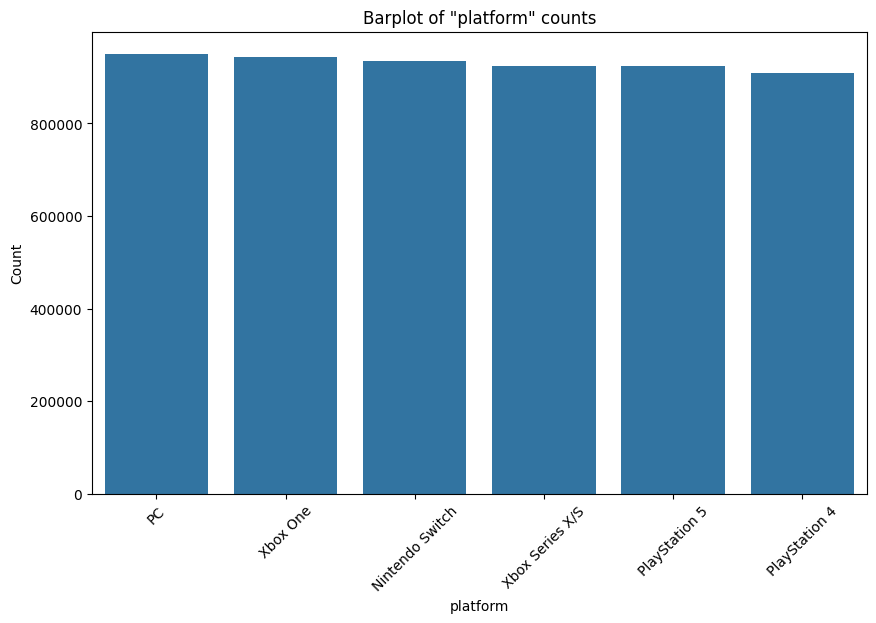

Количество категорий признака genre: 18


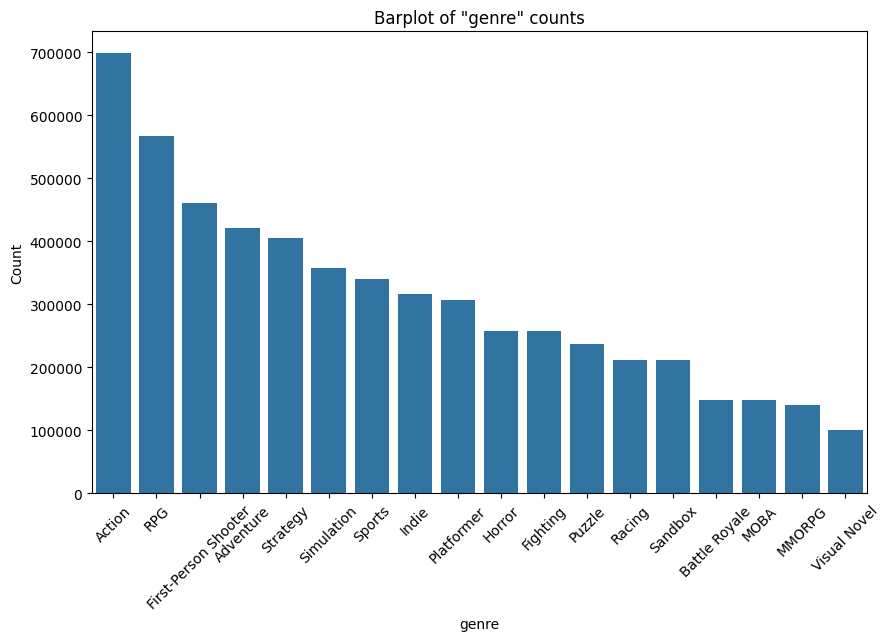

Количество категорий признака storefront: 4


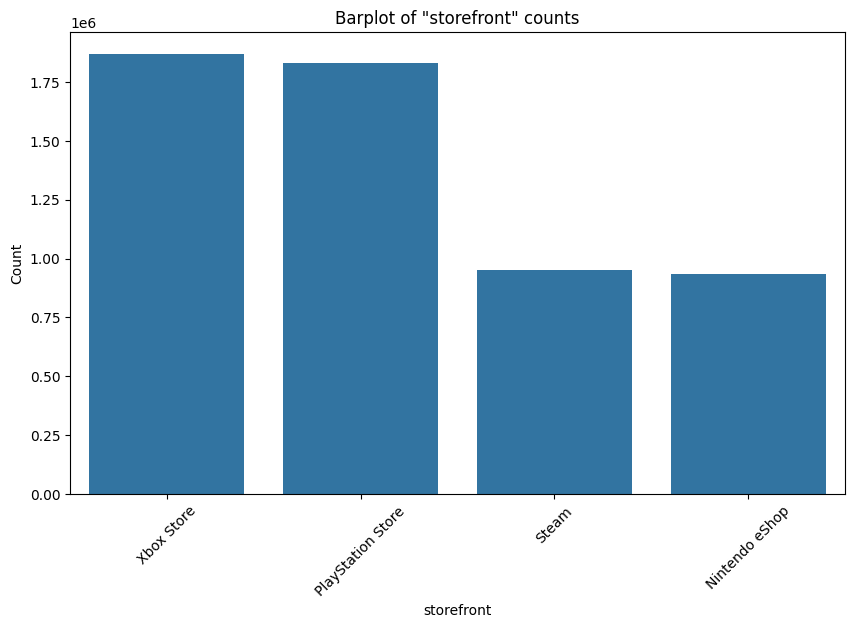

Количество категорий признака age_rating: 16


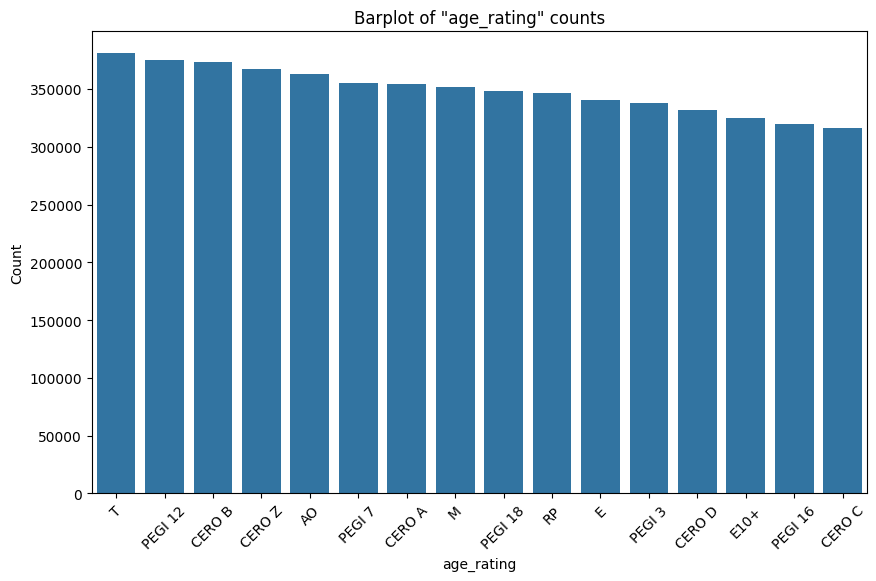

Количество категорий признака publisher_tier: 3


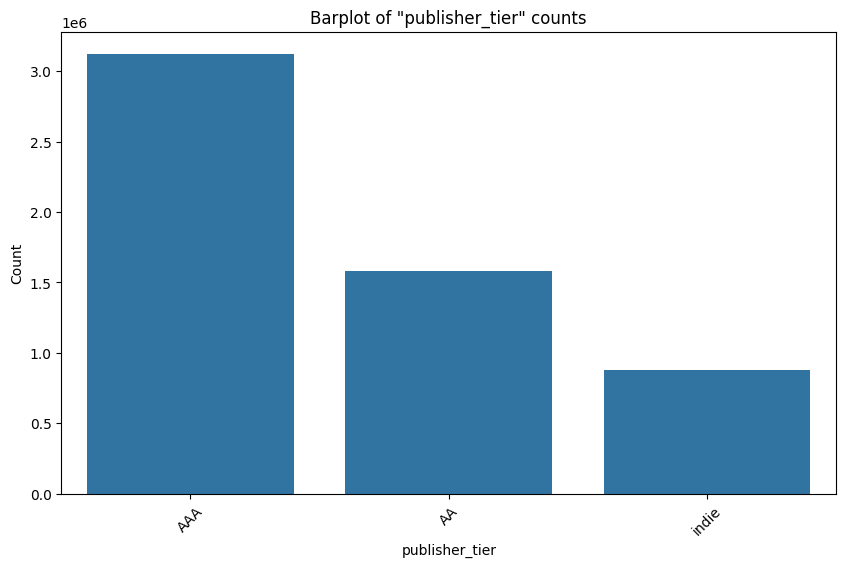

Количество категорий признака sale_event_name: 9


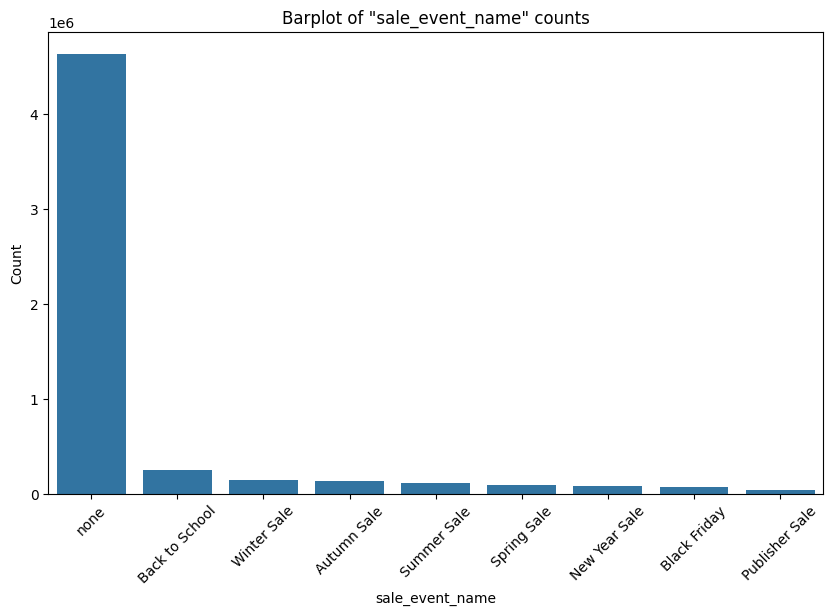

In [16]:
plot_cat_distribution(data=df, column_name="platform")
plot_cat_distribution(data=df, column_name="genre")
plot_cat_distribution(data=df, column_name="storefront")
plot_cat_distribution(data=df, column_name="age_rating")
plot_cat_distribution(data=df, column_name="publisher_tier")
plot_cat_distribution(data=df, column_name="sale_event_name", top_n=15)

In [17]:
count_nulls(data=df, column_name="days_since_release")

days_since_release        NULL:          0 (0.00%)


Минимальное значение:          0.00
Среднее значение:              1312.94
Среднеквадратичное отклонение: 941.90
Первый квартиль:               518.00
Медиана:                       1144.00
Третий квартиль:               1931.00
Максимальное значение:         4380.00


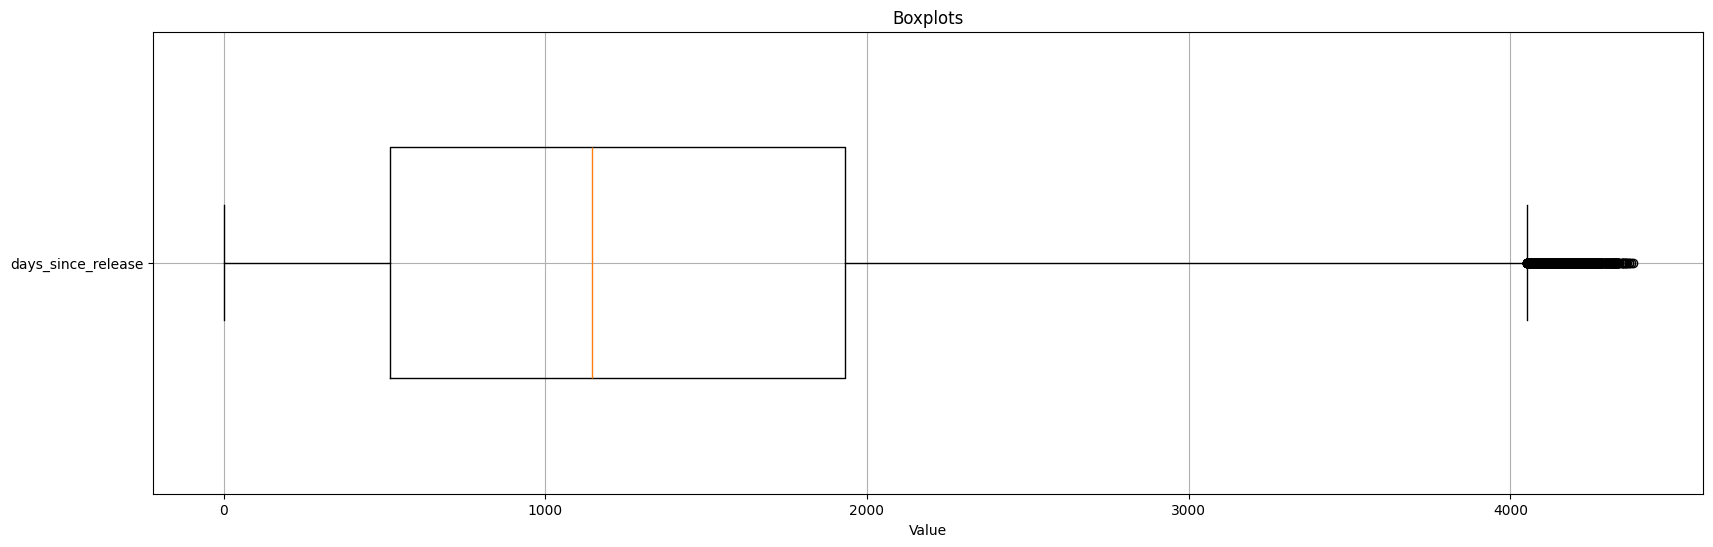

In [18]:
plot_boxplots(data=df, columns=["days_since_release"])

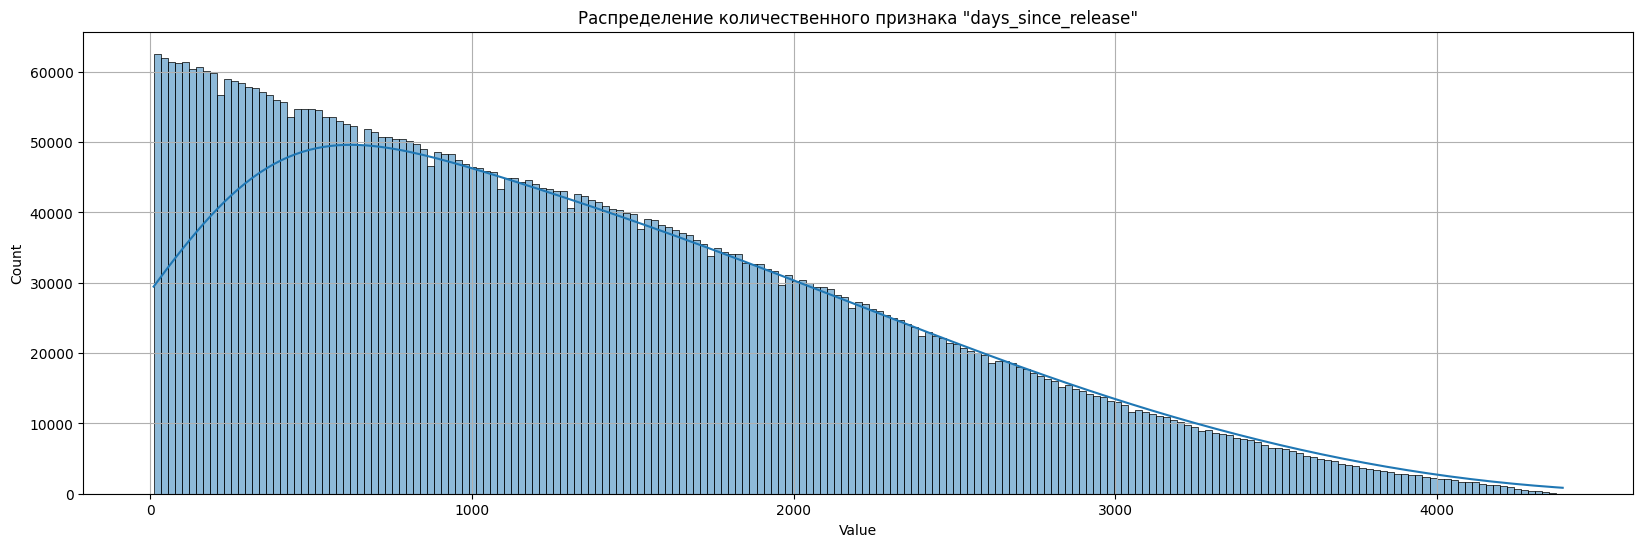

In [19]:
plot_quant_distribution(data=df, column="days_since_release")

Значения больше 2190 дней — выбросы (датасет покрывает 6 лет). Обрезаем.

In [20]:
print(f"Строк с days_since_release > 2190: "
      f"{df.filter(col('days_since_release') > 2190).count()}")

# Обрезка выбросов
df = df.withColumn(
    "days_since_release",
    when(col("days_since_release") > 2190, 2190)
        .otherwise(col("days_since_release"))
)

Строк с days_since_release > 2190: 1068727


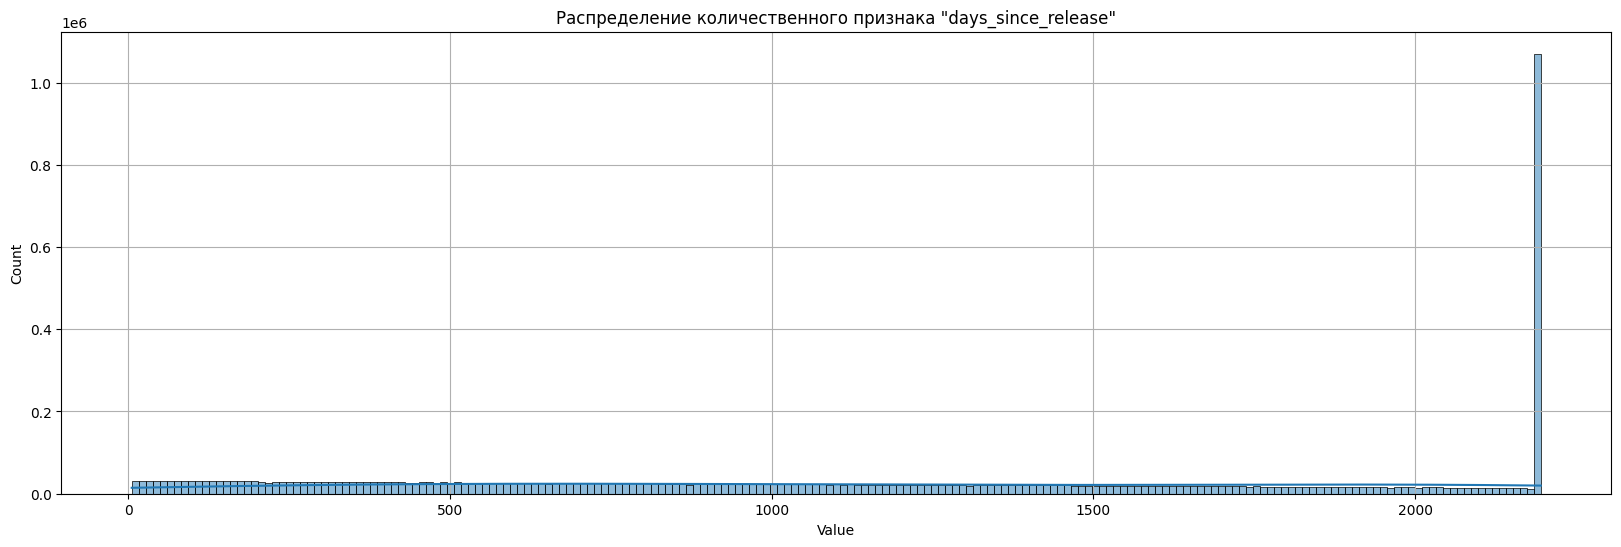

In [21]:
plot_quant_distribution(data=df, column="days_since_release")

Теперь диаграмма более эффективно представляет данные в столбце.

In [22]:
df.show()

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

Анализ столбца `estimated_units_sold`
Тип признака: количественный. Оценка количества проданных копий игры.
Проверим пропуски, построим boxplot и гистограмму распределения.

estimated_units_sold      NULL:          0 (0.00%)


Минимальное значение:          0.00
Среднее значение:              1771806.88
Среднеквадратичное отклонение: 1966828.88
Первый квартиль:               289599.00
Медиана:                       1102401.00
Третий квартиль:               2637591.00
Максимальное значение:         43253008.00


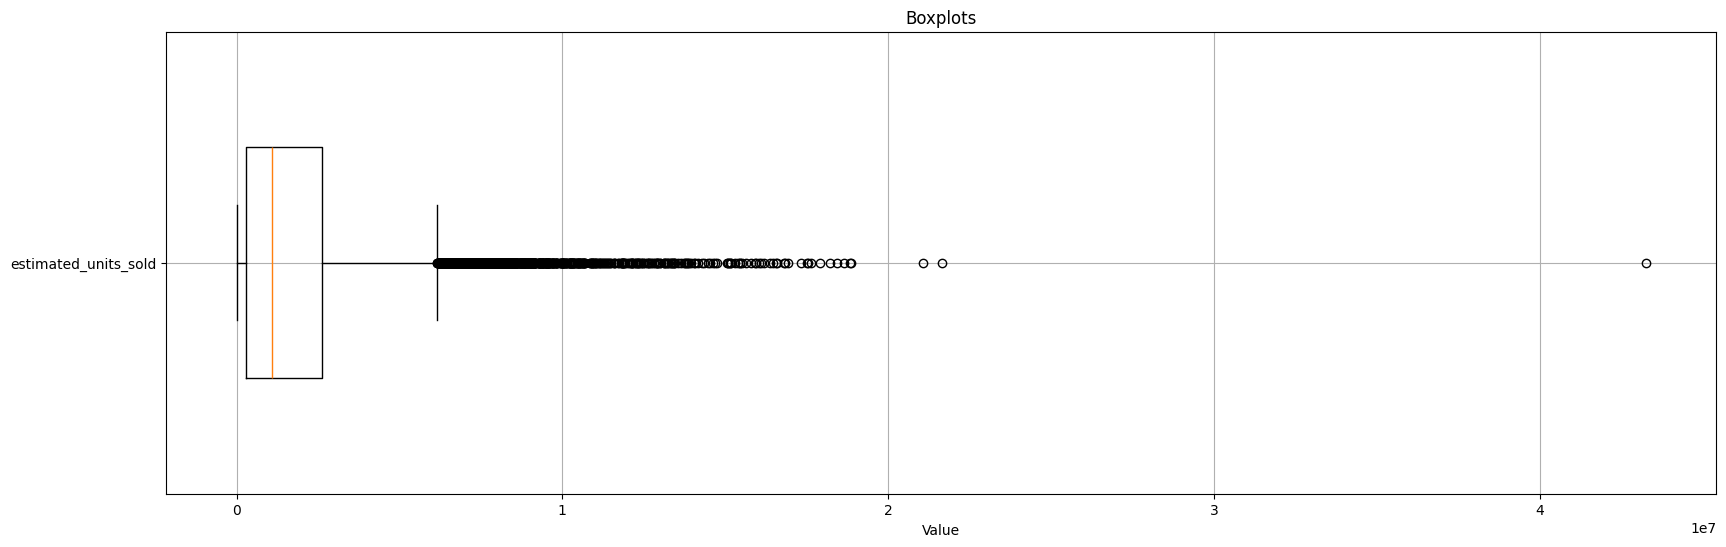

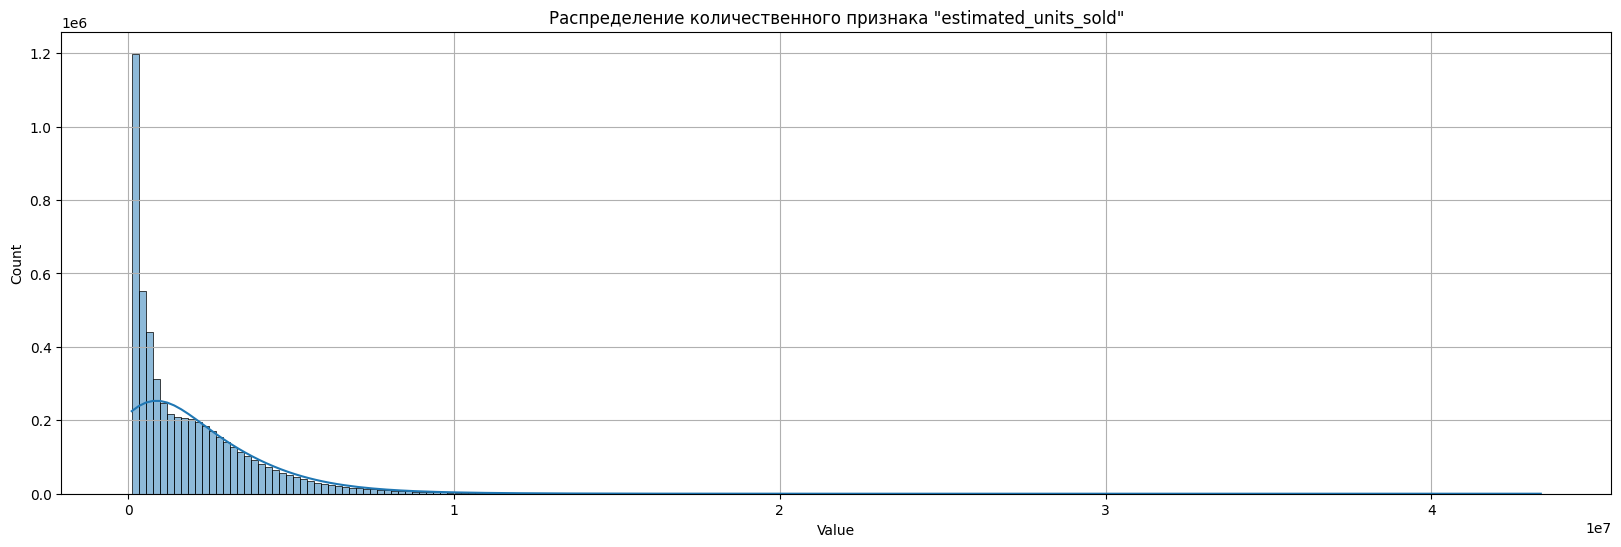

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [43]:
count_nulls(data=df, column_name="estimated_units_sold")

plot_boxplots(data=df, columns=["estimated_units_sold"])

plot_quant_distribution(data=df, column="estimated_units_sold")

df.show()

Анализ столбца `estimated_revenue_usd`
Тип признака: количественный. Оценка выручки в USD.

estimated_revenue_usd     NULL:          0 (0.00%)


Минимальное значение:          0.00
Среднее значение:              56449775.16
Среднеквадратичное отклонение: 71217362.70
Первый квартиль:               6387835.00
Медиана:                       28646632.00
Третий квартиль:               82689184.00
Максимальное значение:         2119094656.00


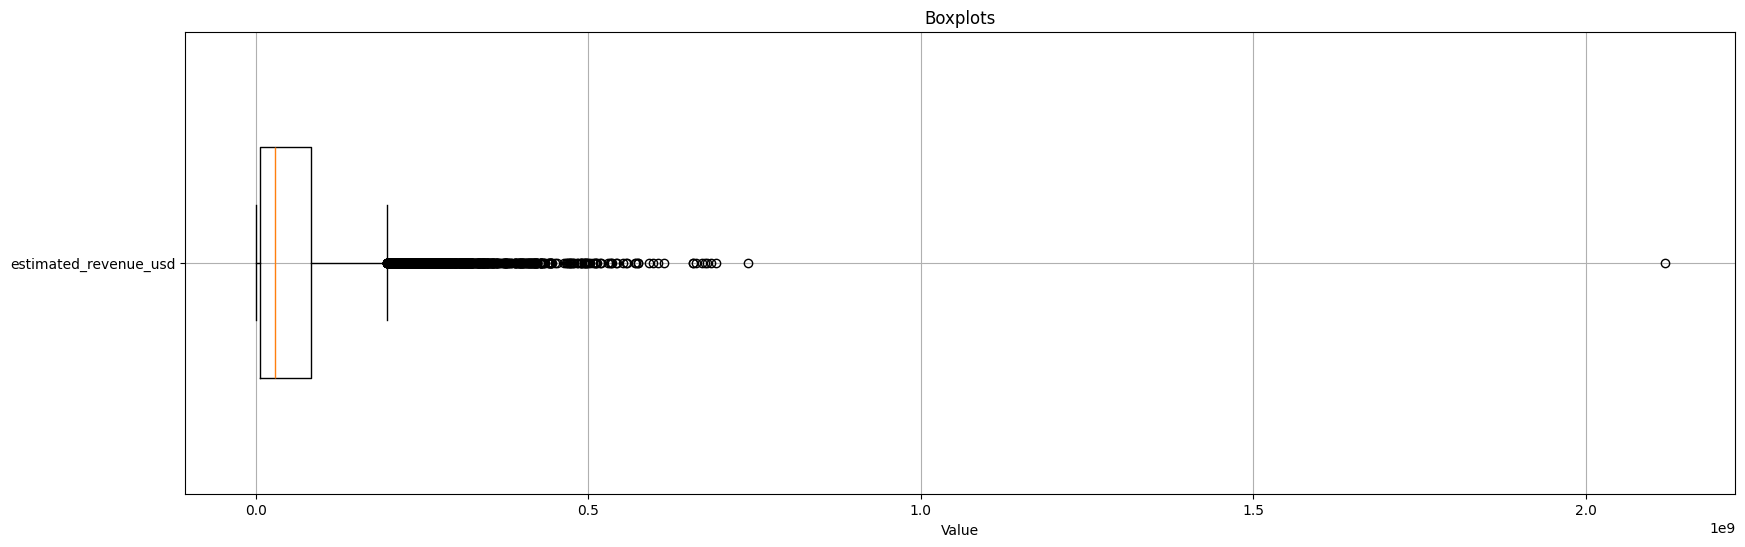

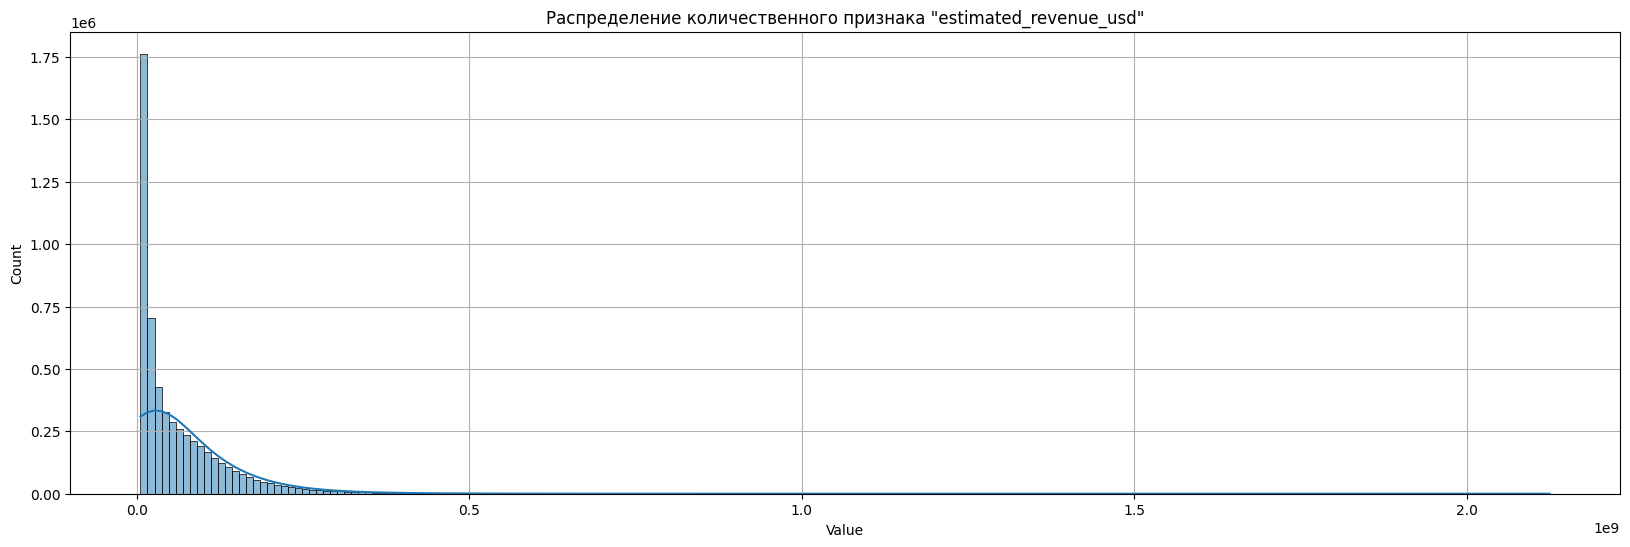

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [24]:
count_nulls(data=df, column_name="estimated_revenue_usd")

plot_boxplots(data=df, columns=["estimated_revenue_usd"])

plot_quant_distribution(data=df, column="estimated_revenue_usd")

df.show()

Анализ столбца `concurrent_players`
Тип признака: количественный. Число одновременных игроков в момент наблюдения.

concurrent_players        NULL:          0 (0.00%)


Минимальное значение:          0.00
Среднее значение:              34040.01
Среднеквадратичное отклонение: 65425.67
Первый квартиль:               960.00
Медиана:                       8288.00
Третий квартиль:               36802.00
Максимальное значение:         2402873.00


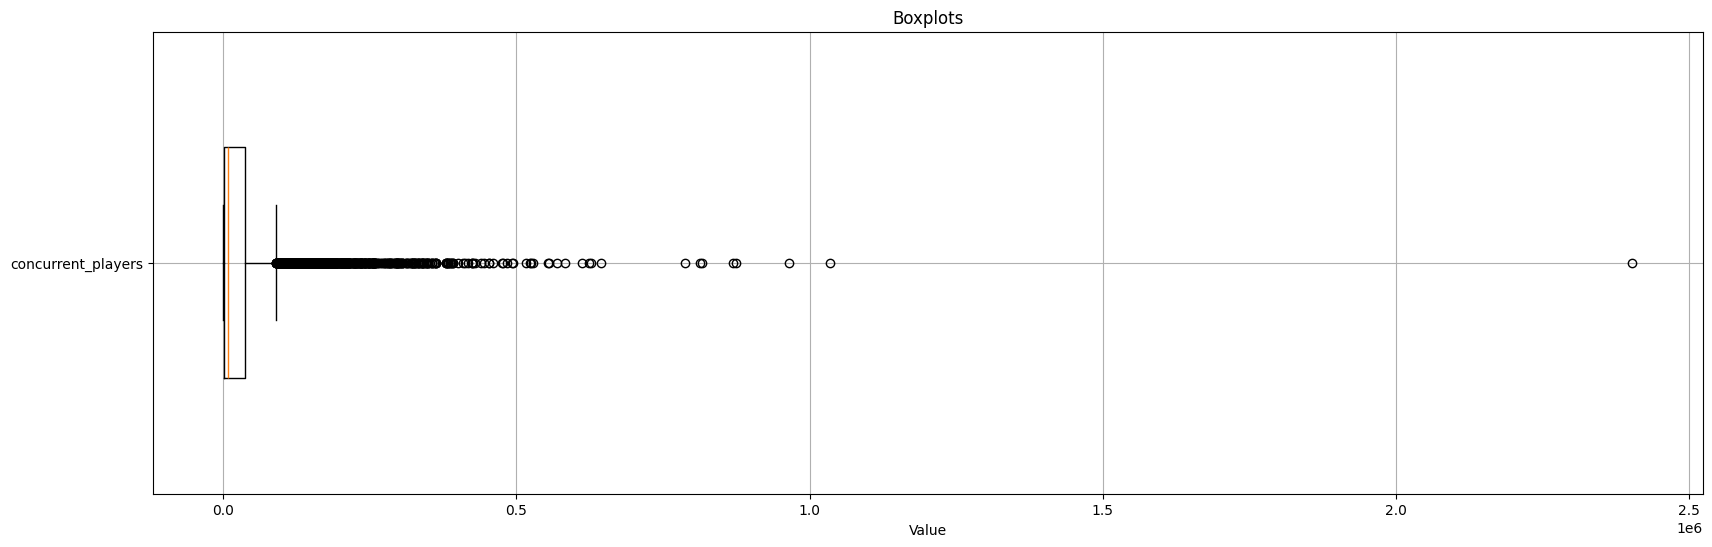

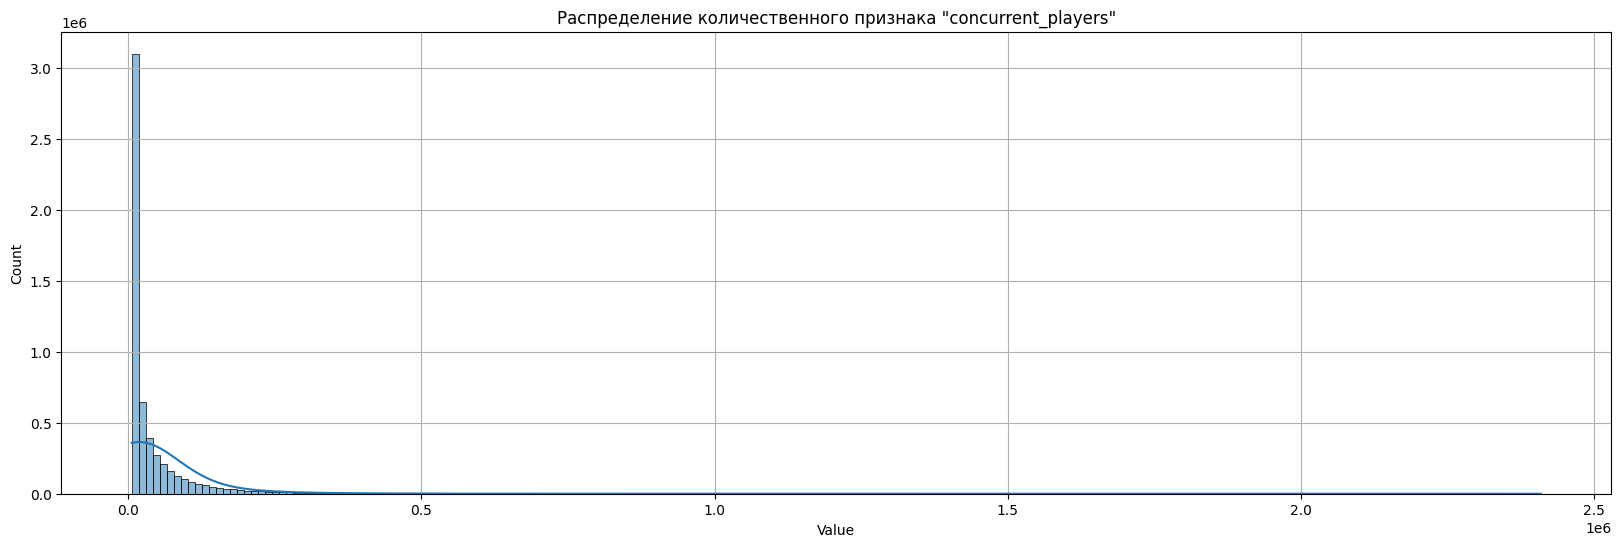

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [25]:
count_nulls(data=df, column_name="concurrent_players")

plot_boxplots(data=df, columns=["concurrent_players"])

plot_quant_distribution(data=df, column="concurrent_players")

df.show()

Анализ столбца `review_count`

Тип признака: количественный. Накопленное число отзывов.

review_count              NULL:          0 (0.00%)


Минимальное значение:          0.00
Среднее значение:              42698.58
Среднеквадратичное отклонение: 39011.20
Первый квартиль:               12655.00
Медиана:                       33030.00
Третий квартиль:               61476.00
Максимальное значение:         565396.00


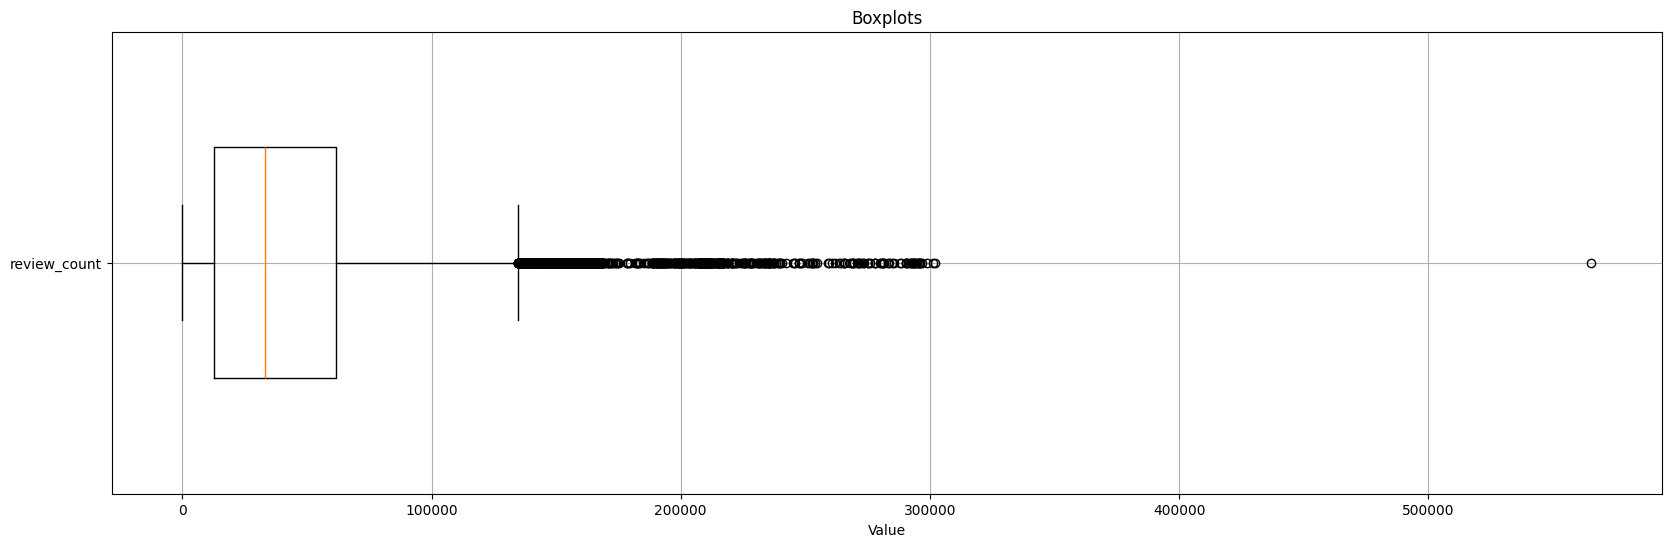

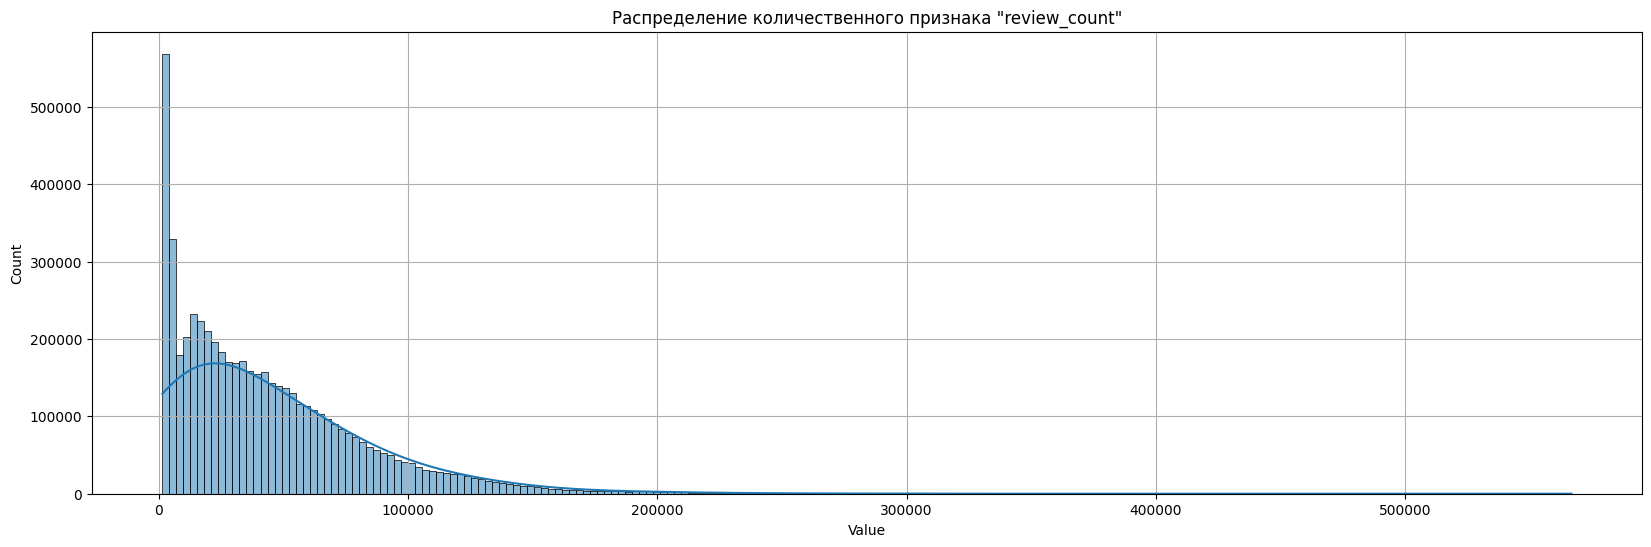

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [26]:
count_nulls(data=df, column_name="review_count")

plot_boxplots(data=df, columns=["review_count"])

plot_quant_distribution(data=df, column="review_count")

df.show()

Анализ столбца `steam_rating_pct`

Тип признака: количественный (доля от 0 до 1). Рейтинг Steam.

steam_rating_pct          NULL:          0 (0.00%)


Минимальное значение:          0.20
Среднее значение:              0.57
Среднеквадратичное отклонение: 0.18
Первый квартиль:               0.42
Медиана:                       0.56
Третий квартиль:               0.70
Максимальное значение:         0.99


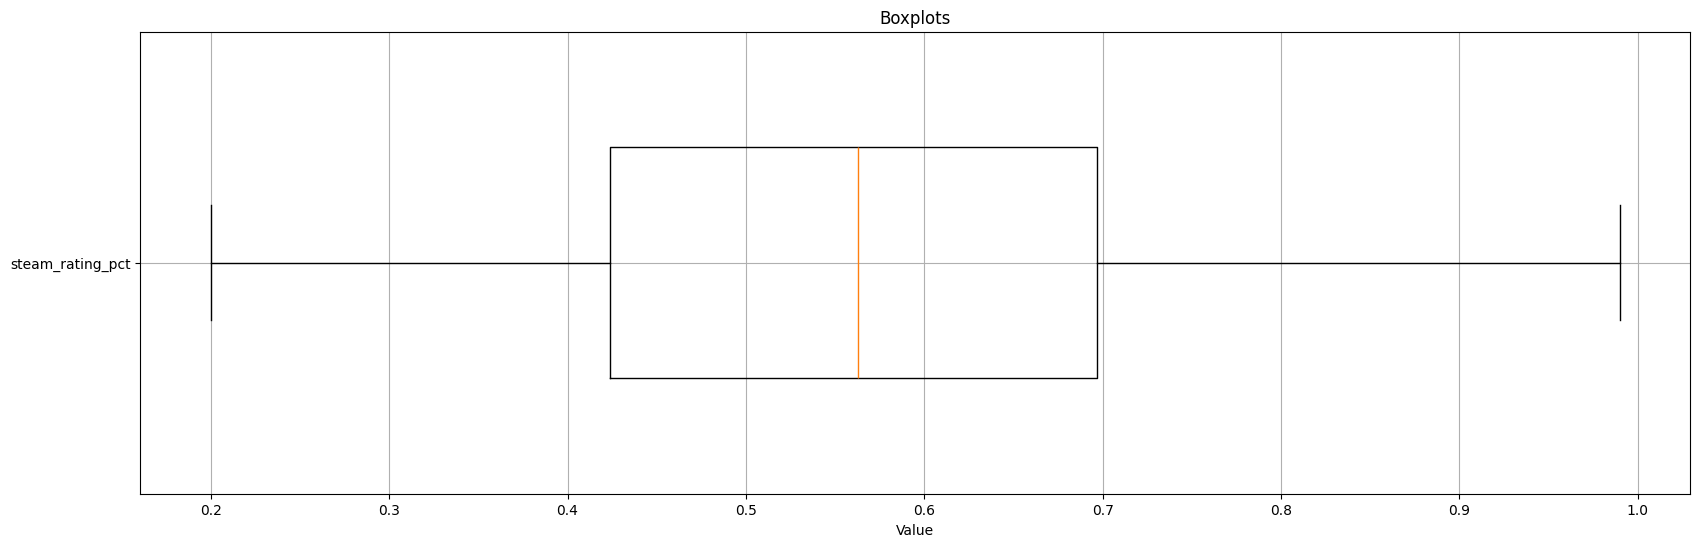

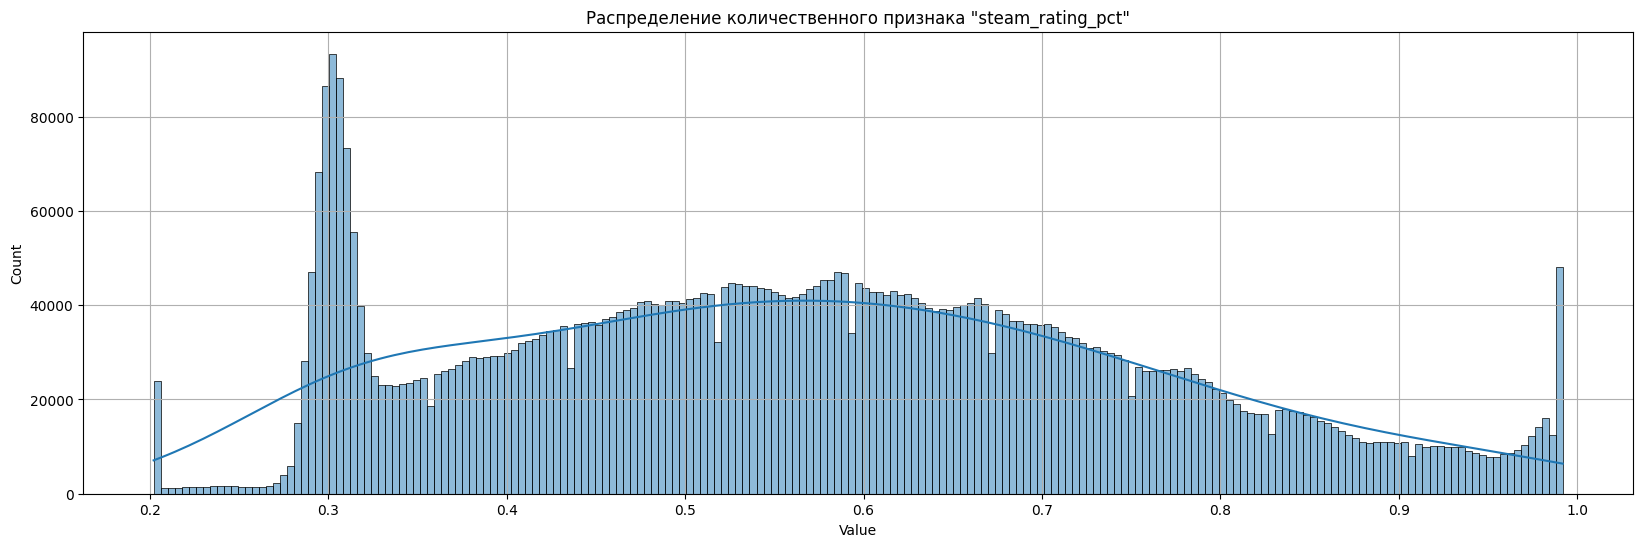

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [27]:
count_nulls(data=df, column_name="steam_rating_pct")

plot_boxplots(data=df, columns=["steam_rating_pct"])

plot_quant_distribution(data=df, column="steam_rating_pct")

df.show()

Анализ столбца `user_score`
Тип признака: количественный. Оценка пользователей.

user_score                NULL:          0 (0.00%)


Минимальное значение:          2.50
Среднее значение:              7.65
Среднеквадратичное отклонение: 1.37
Первый квартиль:               6.80
Медиана:                       7.70
Третий квартиль:               8.70
Максимальное значение:         10.00


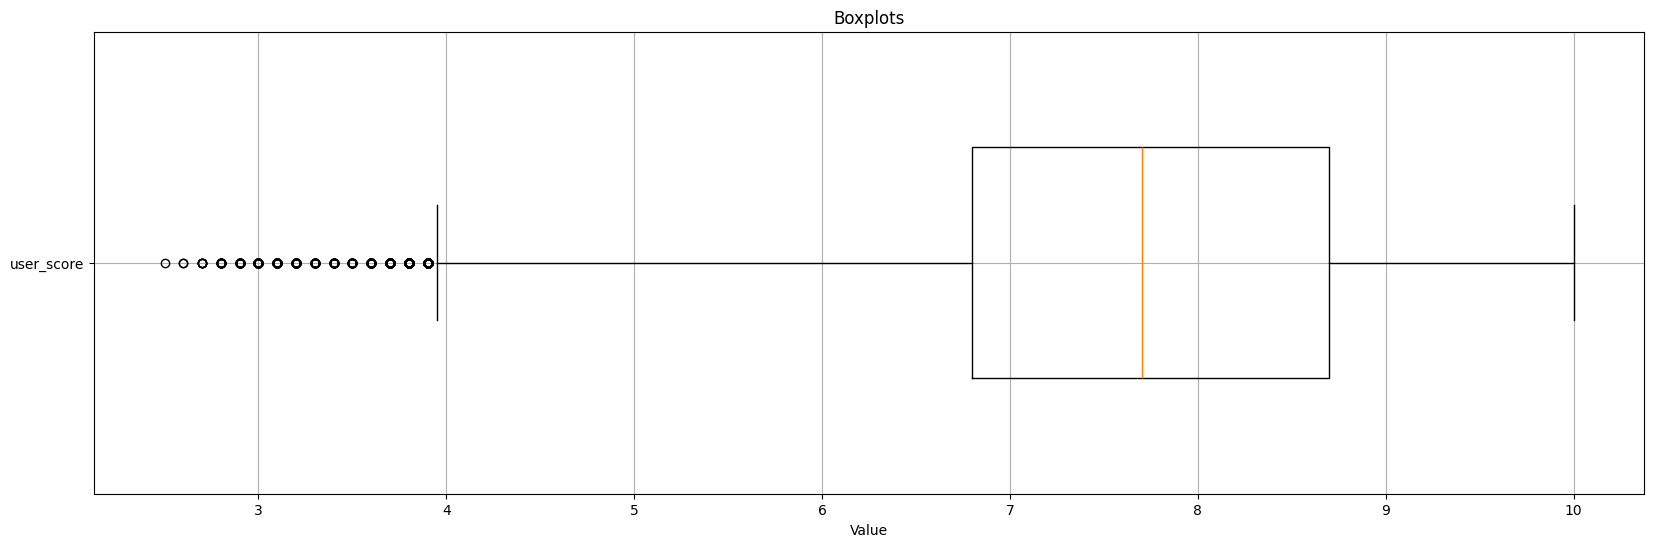

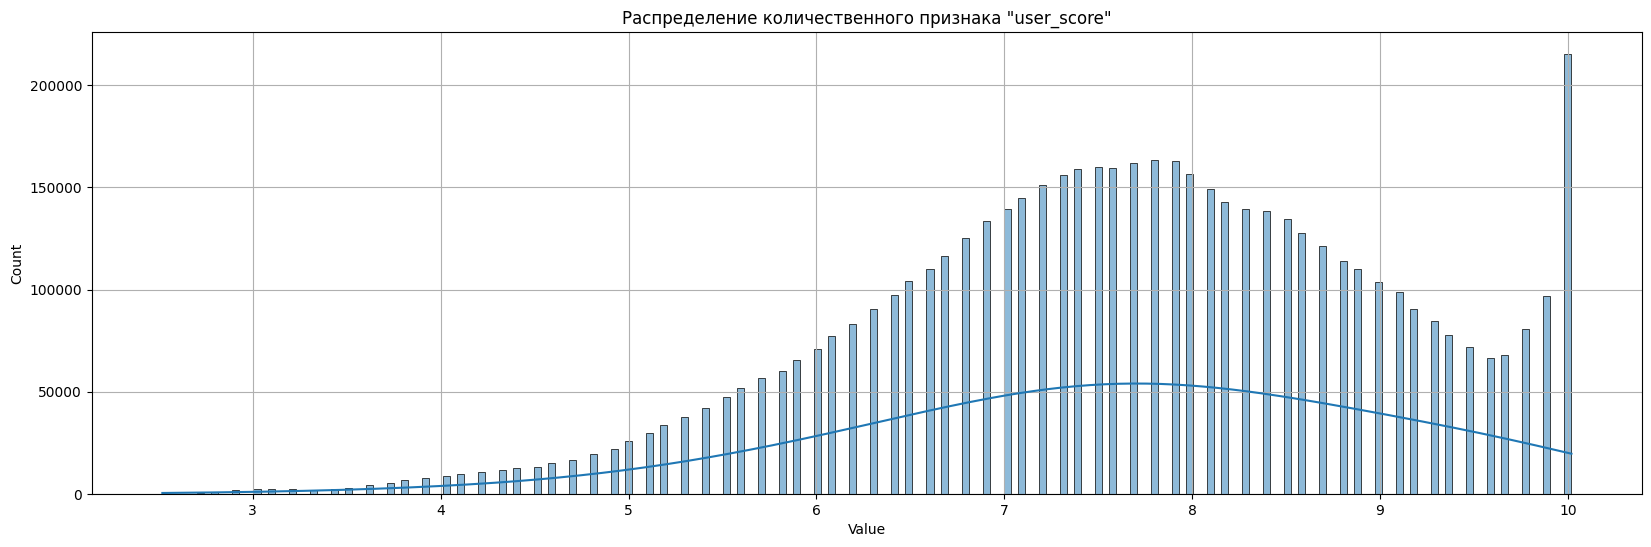

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [28]:
count_nulls(data=df, column_name="user_score")

plot_boxplots(data=df, columns=["user_score"])

plot_quant_distribution(data=df, column="user_score")

df.show()

Анализ столбца `metacritic_score`
Тип признака: количественный. Оценка Metacritic.

metacritic_score          NULL:          0 (0.00%)


Минимальное значение:          22.00
Среднее значение:              73.92
Среднеквадратичное отклонение: 11.77
Первый квартиль:               67.00
Медиана:                       74.00
Третий квартиль:               82.00
Максимальное значение:         99.00


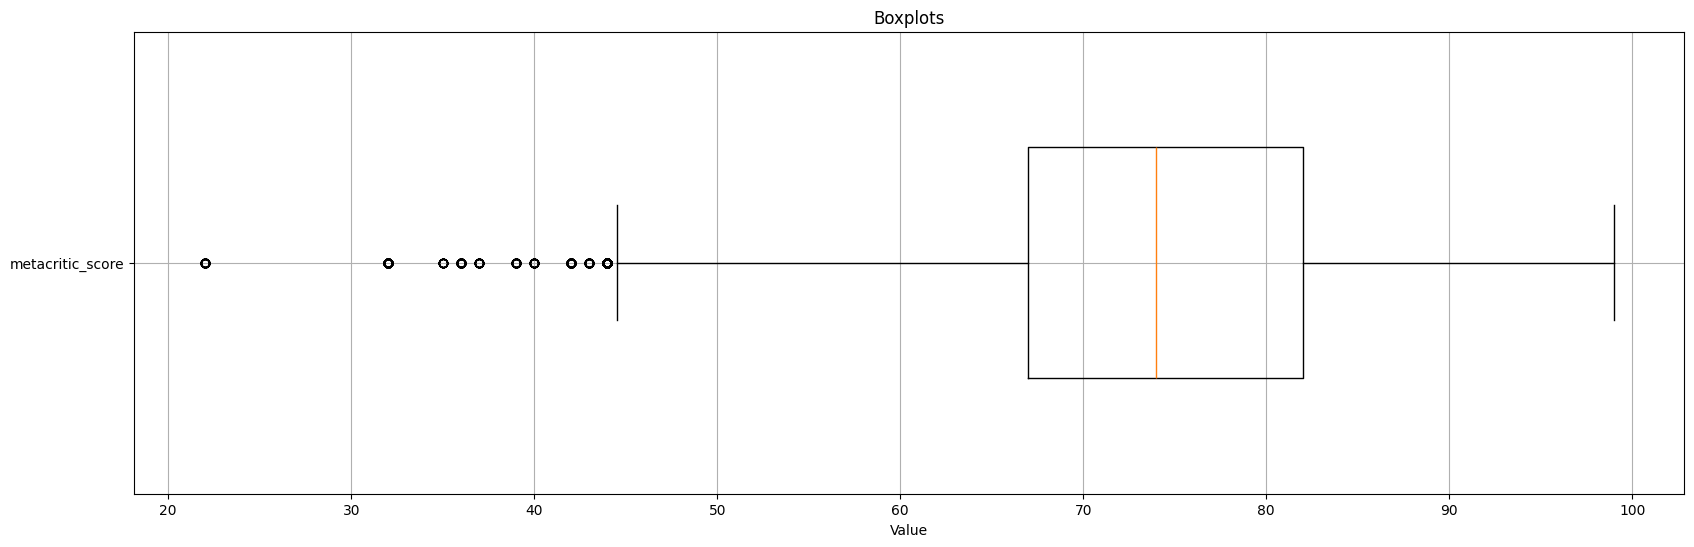

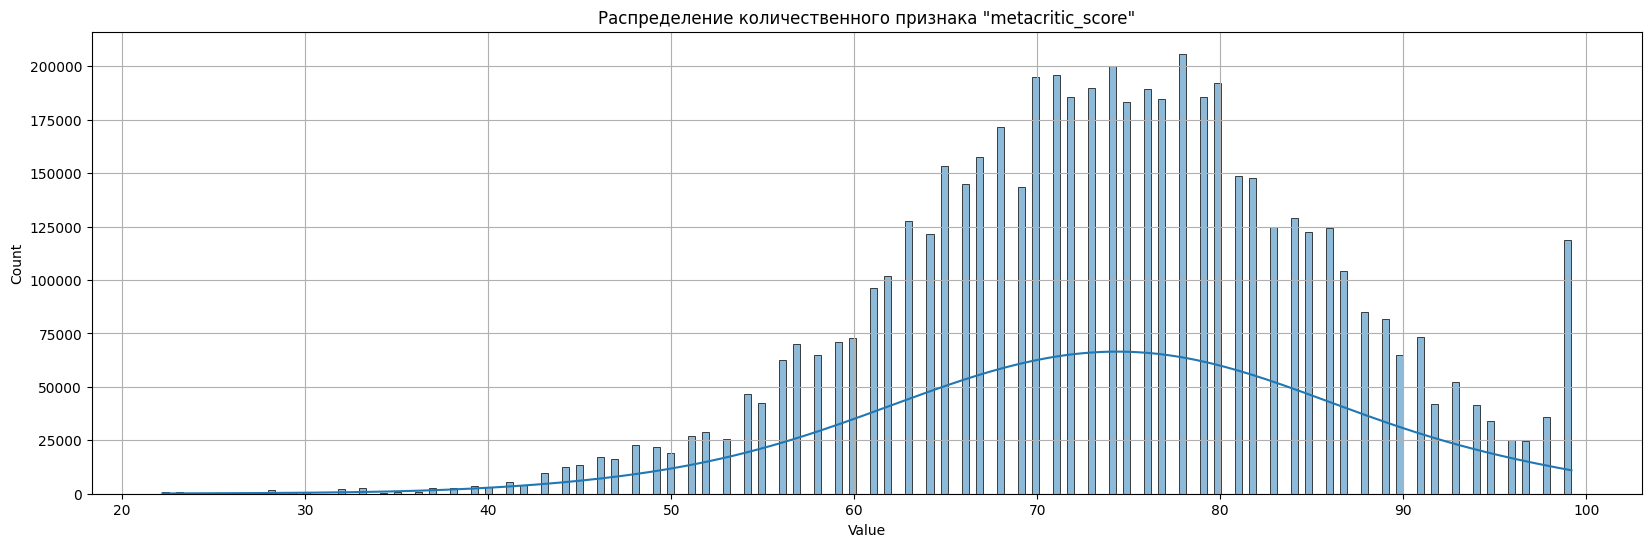

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [29]:
count_nulls(data=df, column_name="metacritic_score")

plot_boxplots(data=df, columns=["metacritic_score"])

plot_quant_distribution(data=df, column="metacritic_score")

df.show()

Анализ столбца `hype_score`
Тип признака: количественный. Индекс «хайпа» вокруг игры.

hype_score                NULL:          0 (0.00%)


Минимальное значение:          0.00
Среднее значение:              14.67
Среднеквадратичное отклонение: 15.28
Первый квартиль:               2.60
Медиана:                       8.45
Третий квартиль:               22.43
Максимальное значение:         90.39


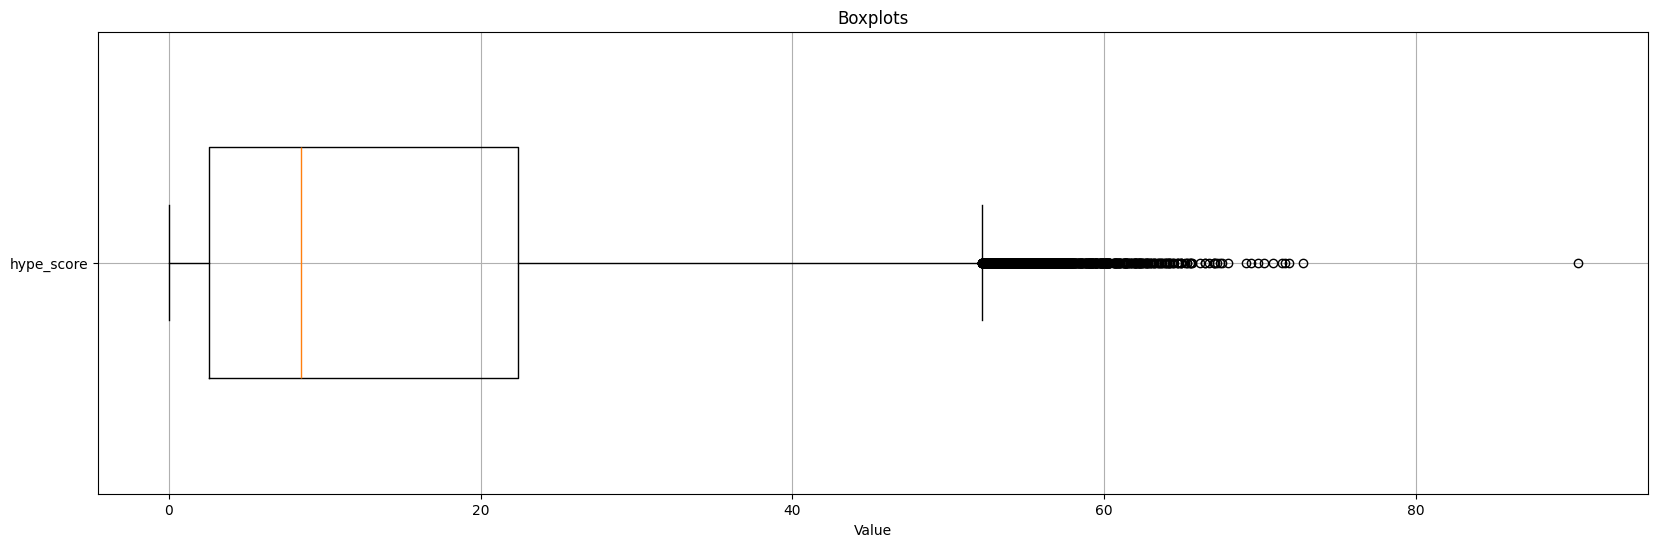

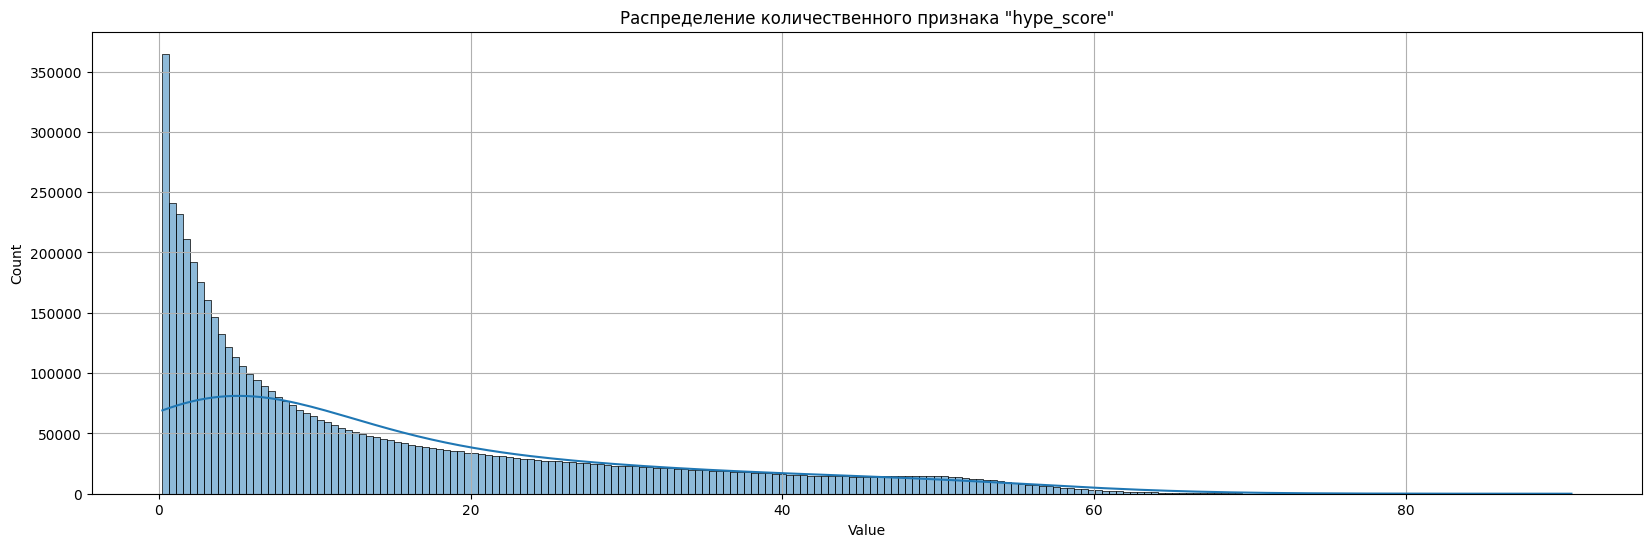

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [30]:
count_nulls(data=df, column_name="hype_score")

plot_boxplots(data=df, columns=["hype_score"])

plot_quant_distribution(data=df, column="hype_score")

df.show()

Анализ признака `current_price_usd`

Признак **количественный**. Все преобразования аналогичны вышерассмотренным.

current_price_usd         NULL:          0 (0.00%)


Минимальное значение:          0.00
Среднее значение:              38.07
Среднеквадратичное отклонение: 21.48
Первый квартиль:               19.99
Медиана:                       37.99
Третий квартиль:               54.99
Максимальное значение:         79.99


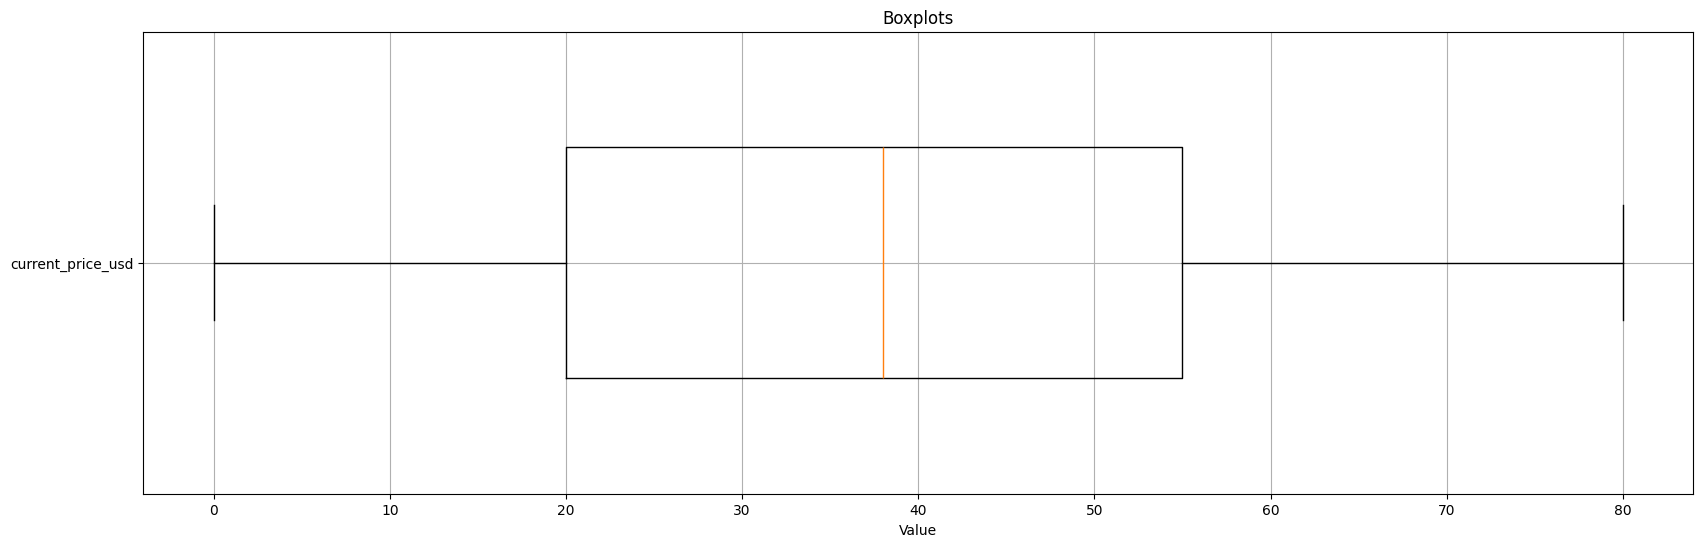

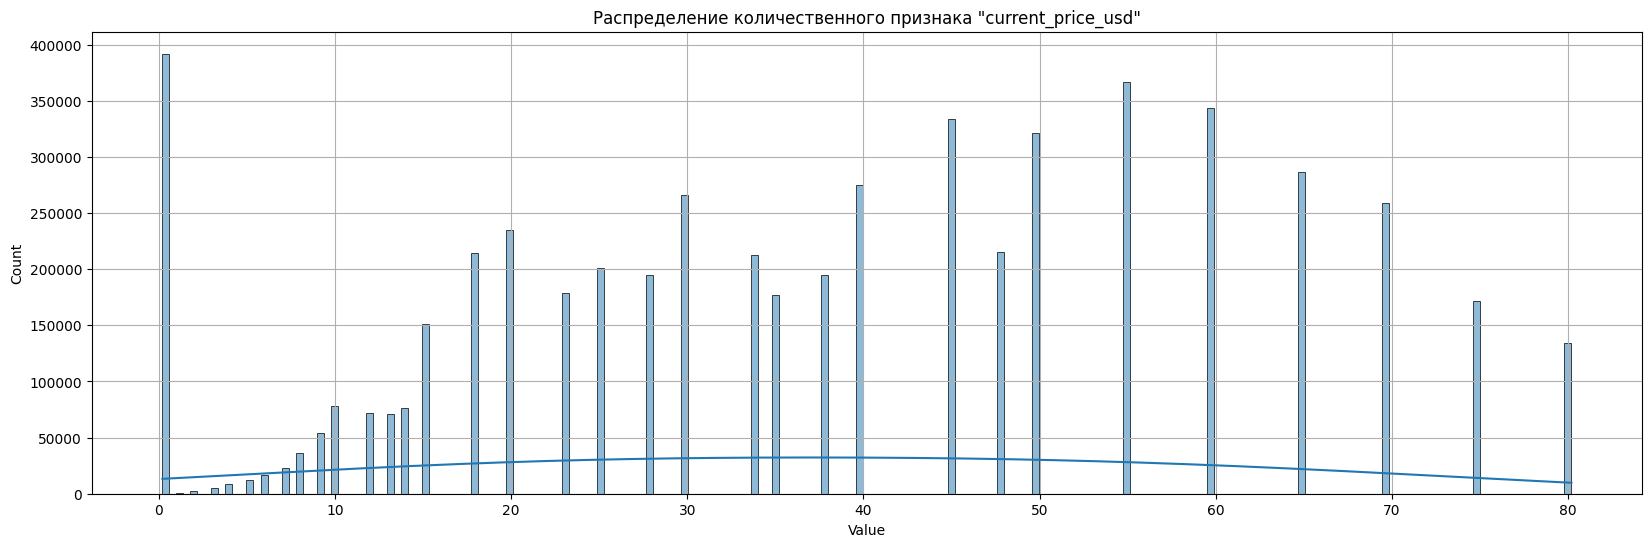

Строк с current_price_usd > 70: 305925
+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|

In [31]:
count_nulls(data=df, column_name="current_price_usd")

plot_boxplots(data=df, columns=["current_price_usd"])

plot_quant_distribution(data=df, column="current_price_usd")

# Смотрим, сколько игр дороже 70 USD
print(f"Строк с current_price_usd > 70: "
      f"{df.filter(col('current_price_usd') > 70).count()}")

df.show()

Анализ столбца `sale_event_name`

Признак **категориальный**.

sale_event_name           NULL:          0 (0.00%)
+---------------+-------+
|sale_event_name|count  |
+---------------+-------+
|none           |4629465|
|Back to School |247875 |
|Winter Sale    |151098 |
|Autumn Sale    |136447 |
|Summer Sale    |113615 |
|Spring Sale    |93863  |
|New Year Sale  |89394  |
|Black Friday   |76145  |
|Publisher Sale |46804  |
+---------------+-------+

Количество категорий признака sale_event_name: 9


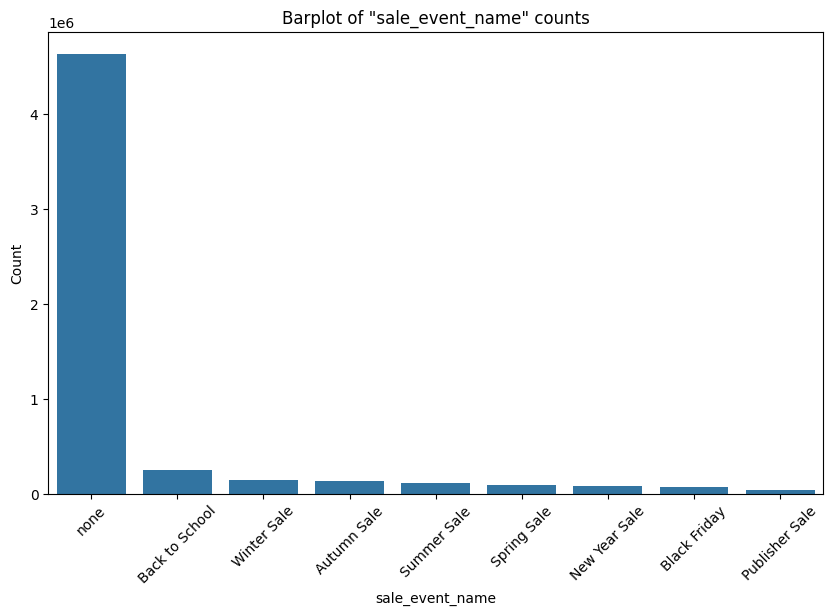

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [32]:
count_nulls(data=df, column_name="sale_event_name")

(
    df
    .groupBy("sale_event_name")
    .count()
    .orderBy("count", ascending=False)
    .show(20, truncate=False)
)

plot_cat_distribution(data=df, column_name="sale_event_name", top_n=15)

df.show()

Анализ столбца `discount_pct`

Признак **количественный**.

discount_pct              NULL:          0 (0.00%)


Минимальное значение:          0.00
Среднее значение:              6.44
Среднеквадратичное отклонение: 16.36
Первый квартиль:               0.00
Медиана:                       0.00
Третий квартиль:               0.00
Максимальное значение:         90.00


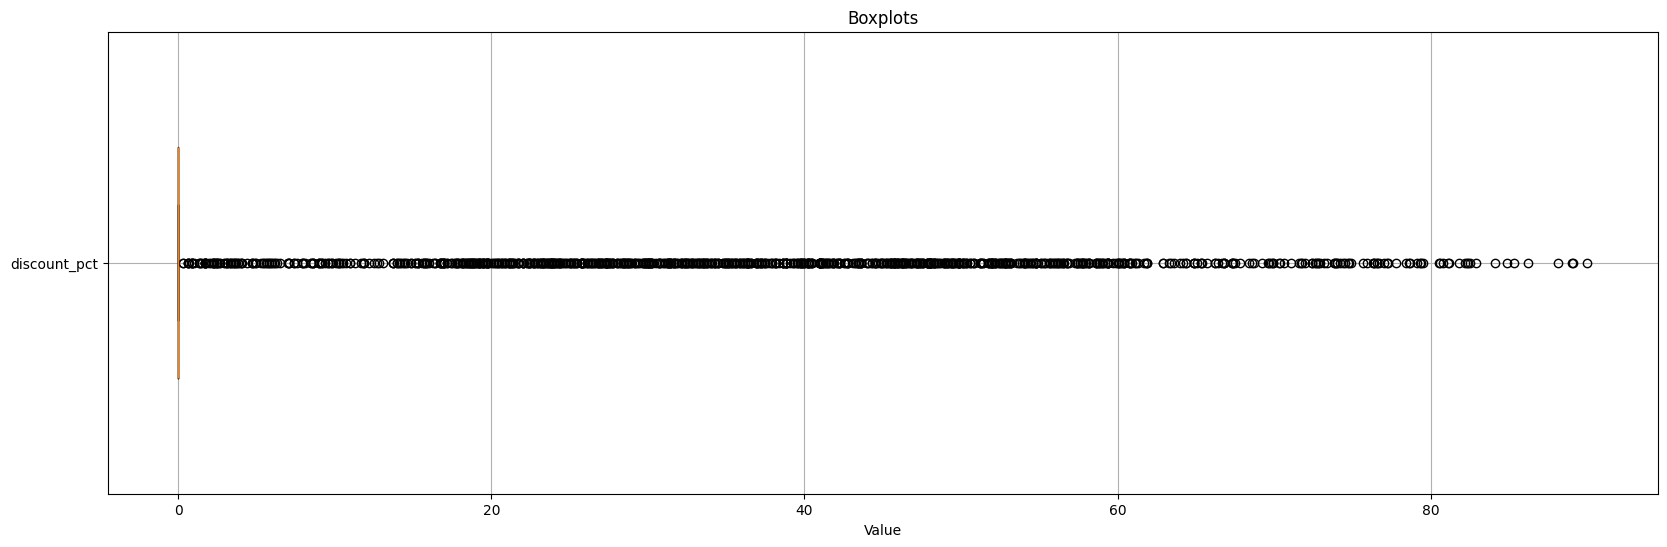

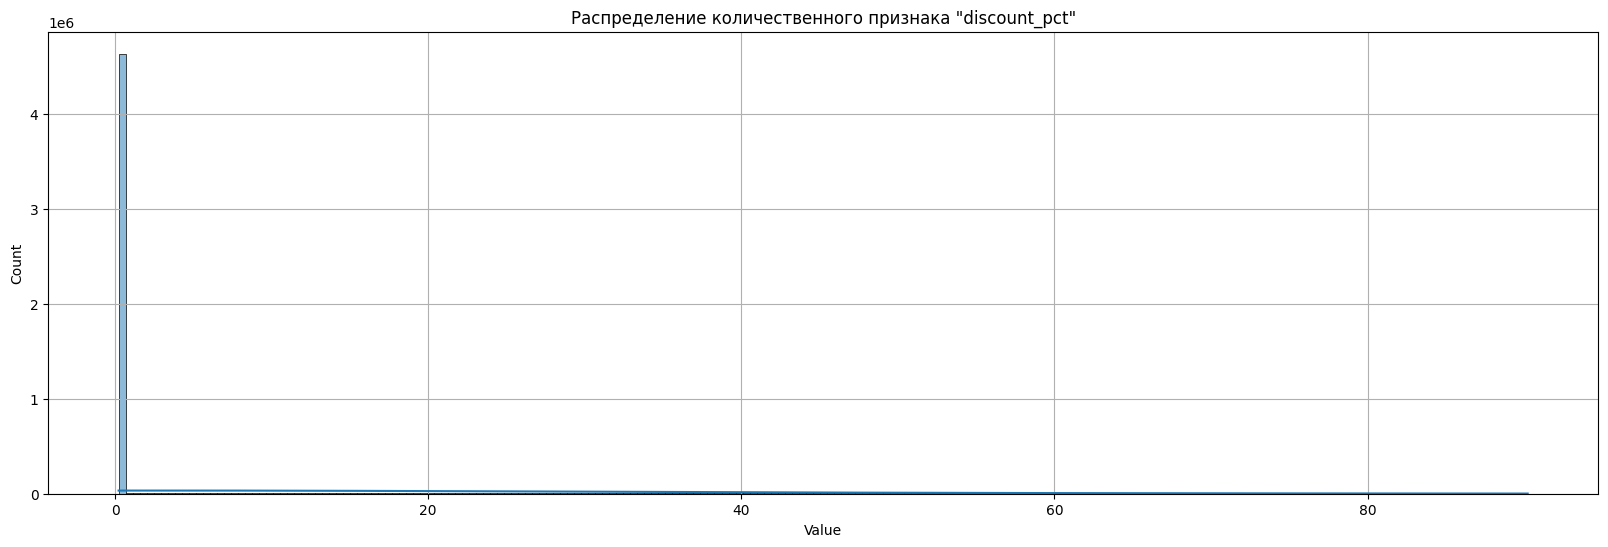

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [33]:
count_nulls(data=df, column_name="discount_pct")

plot_boxplots(data=df, columns=["discount_pct"])

plot_quant_distribution(data=df, column="discount_pct")

df.show()

Анализ признака `release_year`
Тип признака: количественный (2019–2024)

release_year              NULL:          0 (0.00%)


+------------+------+
|release_year| count|
+------------+------+
|        2013|208416|
|        2014|285168|
|        2015|405600|
|        2016|520728|
|        2017|594672|
|        2018|721968|
|        2019|765675|
|        2020|693396|
|        2021|536484|
|        2022|439020|
|        2023|303597|
|        2024|109982|
+------------+------+

Количество категорий признака release_year: 12


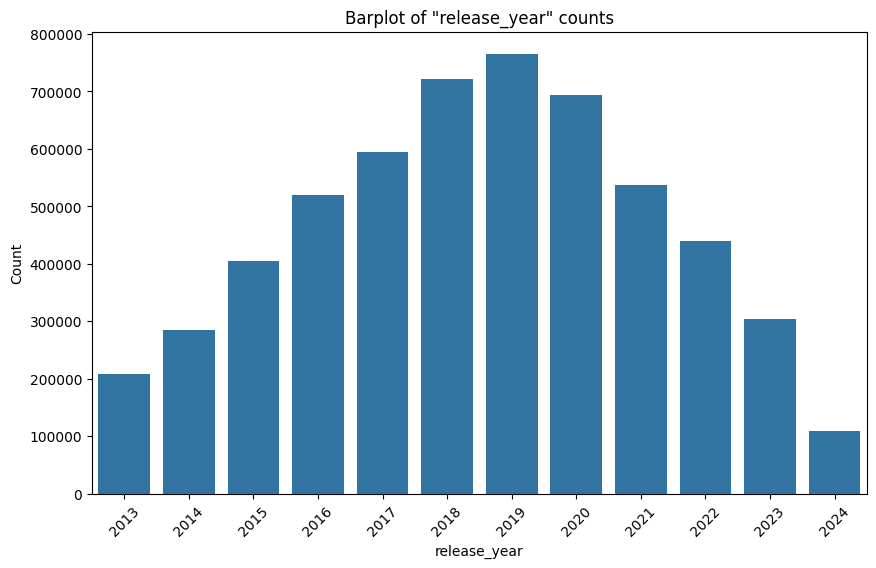

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

In [34]:
count_nulls(data=df, column_name="release_year")

(
    df
    .groupBy("release_year")
    .count()
    .orderBy("release_year")
    .show()
)

plot_cat_distribution(data=df, column_name="release_year")

df.show()

#### Расчет корреляции между количественными признаками

In [35]:
def compute_and_visualize_correlation_matrix(data: DataFrame, 
                                             columns: list[str]) -> None:
    """
    Вычисляет и визуализирует корреляционную матрицу для указанных 
    колонок в DataFrame PySpark.

    Args:
        df (DataFrame): DataFrame PySpark.
        columns (list[str]): Список колонок для вычисления корреляции.

    Returns:
        None
    """
    # Вычисление корреляционной матрицы
    corr_matrix = {}
    for col1 in columns:
        corr_matrix[col1] = {}
        for col2 in columns:
            corr_value = data.select(corr(col1, col2)).collect()[0][0]
            corr_matrix[col1][col2] = corr_value

    # Преобразование корреляционной матрицы в DataFrame Pandas для визуализации
    corr_matrix_pd = pd.DataFrame(corr_matrix)

    # Построение и визуализация корреляционной матрицы
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix_pd, annot=True, cmap='coolwarm', linewidths=0.5)
    plt.title('Correlation Matrix')
    plt.show()

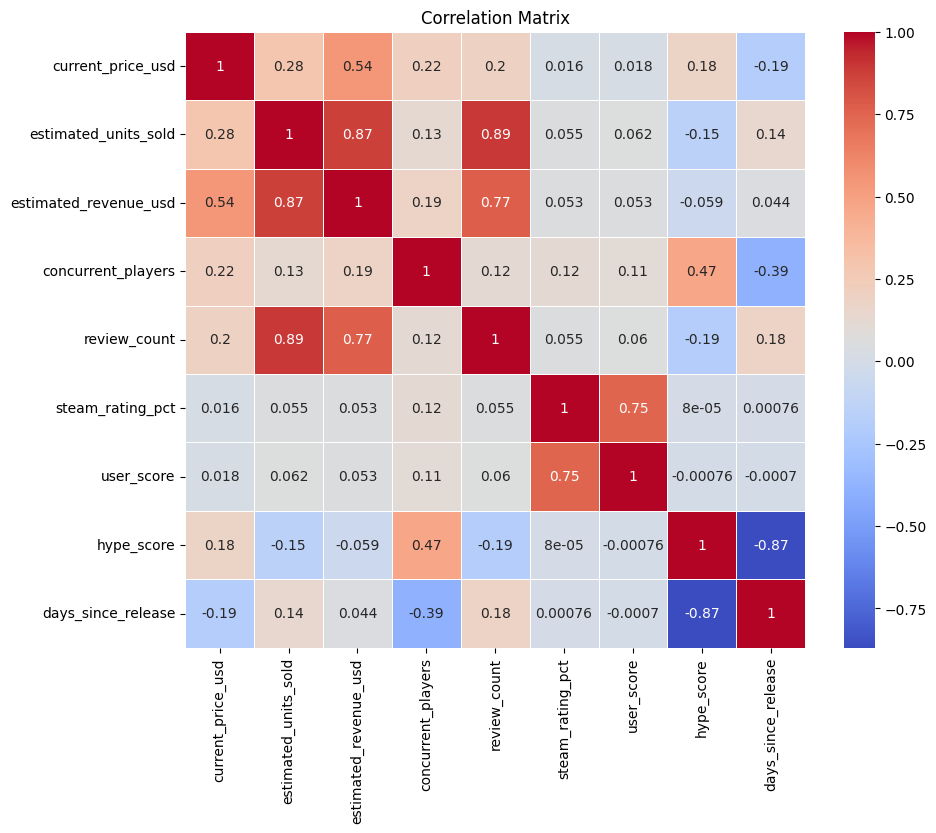

In [36]:
compute_and_visualize_correlation_matrix(
    data=df, columns=[
        "current_price_usd", "estimated_units_sold", "estimated_revenue_usd",
        "concurrent_players", "review_count", "steam_rating_pct",
        "user_score", "hype_score", "days_since_release"
    ]
)

Корреляционная матрица демонстрирует наличие корреляции между некоторыми количественными признаками.

In [37]:
df.show()

+---------+--------------+---------------+--------------+------+--------------+----------+---------------+-----------------+------------------+------------+--------------------+---------------------+------------------+----------------+------------+----------------+----------------+----------------+----------+----------------+--------------+--------------------+-------------------+---------------+-----------------+----------+--------------+------------+-------------+------------------+--------+--------+--------+--------+--------+--------+
|  game_id|     game_name|       platform|    storefront| genre|publisher_tier|age_rating|sale_event_name|current_price_usd|original_price_usd|discount_pct|estimated_units_sold|estimated_revenue_usd|concurrent_players|peak_ccu_alltime|review_count|positive_reviews|negative_reviews|steam_rating_pct|user_score|metacritic_score|wishlist_count|twitch_viewers_proxy|youtube_views_proxy|reddit_mentions|social_hype_index|hype_score|virality_score|release_year|

Посмотрим, сколько объектов осталось после преобразований датасета.

In [38]:
df.count()

5584706

In [39]:
df.printSchema()

root
 |-- game_id: string (nullable = true)
 |-- game_name: string (nullable = true)
 |-- platform: string (nullable = true)
 |-- storefront: string (nullable = true)
 |-- genre: string (nullable = true)
 |-- publisher_tier: string (nullable = true)
 |-- age_rating: string (nullable = true)
 |-- sale_event_name: string (nullable = true)
 |-- current_price_usd: float (nullable = true)
 |-- original_price_usd: float (nullable = true)
 |-- discount_pct: float (nullable = true)
 |-- estimated_units_sold: float (nullable = true)
 |-- estimated_revenue_usd: float (nullable = true)
 |-- concurrent_players: float (nullable = true)
 |-- peak_ccu_alltime: float (nullable = true)
 |-- review_count: integer (nullable = true)
 |-- positive_reviews: integer (nullable = true)
 |-- negative_reviews: integer (nullable = true)
 |-- steam_rating_pct: float (nullable = true)
 |-- user_score: float (nullable = true)
 |-- metacritic_score: float (nullable = true)
 |-- wishlist_count: integer (nullable = tru

Сохраняет очищенную и обработанную таблицу на диск.

In [40]:
spark.sql("DROP TABLE IF EXISTS spark_catalog.krutov_database.sobd_lab1_processed_table")

# Сохраняем очищенную таблицу
df.writeTo("sobd_lab1_processed_table").using("iceberg").createOrReplace()

26/09/17 21:24:03 WARN HadoopTableOperations: Error reading version hint file hdfs:/user/user0/warehouse/krutov_database/sobd_lab1_processed_table/metadata/version-hint.text
java.io.FileNotFoundException: File does not exist: /user/user0/warehouse/krutov_database/sobd_lab1_processed_table/metadata/version-hint.text
	at org.apache.hadoop.hdfs.server.namenode.INodeFile.valueOf(INodeFile.java:87)
	at org.apache.hadoop.hdfs.server.namenode.INodeFile.valueOf(INodeFile.java:77)
	at org.apache.hadoop.hdfs.server.namenode.FSDirStatAndListingOp.getBlockLocations(FSDirStatAndListingOp.java:159)
	at org.apache.hadoop.hdfs.server.namenode.FSNamesystem.getBlockLocations(FSNamesystem.java:2198)
	at org.apache.hadoop.hdfs.server.namenode.NameNodeRpcServer.getBlockLocations(NameNodeRpcServer.java:795)
	at org.apache.hadoop.hdfs.protocolPB.ClientNamenodeProtocolServerSideTranslatorPB.getBlockLocations(ClientNamenodeProtocolServerSideTranslatorPB.java:468)
	at org.apache.hadoop.hdfs.protocol.proto.Clien

In [41]:
for table in spark.catalog.listTables():
    print(table.name)

df_check = spark.table("spark_catalog.krutov_database.sobd_lab1_processed_table")
print(f"Строк: {df_check.count()}")
print(f"Колонок: {len(df_check.columns)}")
df_check.printSchema()

sobd_lab1_processed_table
sobd_lab1_table
Строк: 5584706
Колонок: 37
root
 |-- game_id: string (nullable = true)
 |-- game_name: string (nullable = true)
 |-- platform: string (nullable = true)
 |-- storefront: string (nullable = true)
 |-- genre: string (nullable = true)
 |-- publisher_tier: string (nullable = true)
 |-- age_rating: string (nullable = true)
 |-- sale_event_name: string (nullable = true)
 |-- current_price_usd: float (nullable = true)
 |-- original_price_usd: float (nullable = true)
 |-- discount_pct: float (nullable = true)
 |-- estimated_units_sold: float (nullable = true)
 |-- estimated_revenue_usd: float (nullable = true)
 |-- concurrent_players: float (nullable = true)
 |-- peak_ccu_alltime: float (nullable = true)
 |-- review_count: integer (nullable = true)
 |-- positive_reviews: integer (nullable = true)
 |-- negative_reviews: integer (nullable = true)
 |-- steam_rating_pct: float (nullable = true)
 |-- user_score: float (nullable = true)
 |-- metacritic_score:

Обратите внимание, что при необходимости созданные базу данных и таблицу можно удалить следующими командами.

In [45]:
# spark.sql("DROP TABLE spark_catalog.krutov_database.sobd_lab1_processed_table")
# spark.sql("DROP DATABASE spark_catalog.krutov_database")

Останавливаем `Spark`-сессию.

In [46]:
spark.stop()